# 04. Multivariate LSTM with Geographical Features

This notebook develops and compares two multivariate LSTM models (Model A and Model B) for next-day maximum temperature prediction across 50 Indian cities.
- **Model A**: 8 temporal features + Latitude, Longitude, Elevation + City Embedding
- **Model B**: 8 temporal features + Latitude, Longitude, Elevation, **Coastal Distance** + City Embedding

## 1. Load Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "india_weather_merged.csv"

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (124700, 19)


,date,city,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,state,region,latitude,longitude,elevation_m
0,2020-01-01,Agartala,26.2,16.2,20.5,28.3,0.3,3.0,79,11.5,60,11.62,2.29,51,Tripura,Northeast,23.8315,91.2868,12.0
1,2020-01-02,Agartala,26.5,15.0,20.2,28.8,0.0,0.0,86,8.0,30,11.70,2.25,3,Tripura,Northeast,23.8315,91.2868,12.0
2,2020-01-03,Agartala,20.2,15.7,18.0,21.4,18.5,16.0,90,17.1,27,5.77,1.14,63,Tripura,Northeast,23.8315,91.2868,12.0
3,2020-01-04,Agartala,21.8,14.7,17.9,22.7,0.6,2.0,86,9.4,221,8.38,1.62,51,Tripura,Northeast,23.8315,91.2868,12.0
4,2020-01-05,Agartala,21.8,13.6,17.0,22.1,0.0,0.0,85,8.7,358,9.72,1.82,3,Tripura,Northeast,23.8315,91.2868,12.0


## 2. City Geographical Metadata

In [3]:
geo_columns = [
    "city",
    "state",
    "latitude",
    "longitude",
    "elevation_m"
]

city_geo = (
    df[geo_columns]
    .drop_duplicates(subset="city")
    .sort_values("city")
    .reset_index(drop=True)
)

print("Unique cities:", len(city_geo))
display(city_geo.head())

Unique cities: 50


,city,state,latitude,longitude,elevation_m
0,Agartala,Tripura,23.8315,91.2868,12.0
1,Agra,Uttar Pradesh,27.1767,78.0081,170.0
2,Ahmedabad,Gujarat,23.0225,72.5714,53.0
3,Amritsar,Punjab,31.6340,74.8723,234.0
4,Bengaluru,Karnataka,12.9716,77.5946,910.0


## 3. Coastal Distance Feature Engineering (Natural Earth)

In [4]:
import importlib.util

libraries = ["geopandas", "shapely", "pyproj"]

for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if installed else 'Not installed'}")

geopandas: Installed
shapely: Installed
pyproj: Installed


In [5]:
import geopandas as gpd

COASTLINE_PATH = (
    PROJECT_ROOT / "data" / "raw" / "coastline" / "ne_10m_coastline.shp"
)

coastline = gpd.read_file(COASTLINE_PATH)

print("Number of coastline features:", len(coastline))
print("Coordinate Reference System:", coastline.crs)
display(coastline.head(2))

Number of coastline features: 4133
Coordinate Reference System: EPSG:4326


,featurecla,scalerank,min_zoom,geometry
0,Coastline,0,0.0,"LINESTRING (59.91603 -67.40049, 59.67856 -67.3..."
1,Coastline,0,0.0,"LINESTRING (-51.73062 -82.0626, -52.18688 -82...."


In [6]:
# Convert coastline geometries into a projected CRS
coastline_projected = coastline.to_crs(epsg=7755)

print("Original CRS:", coastline.crs)
print("Projected CRS:", coastline_projected.crs)

Original CRS: EPSG:4326
Projected CRS: EPSG:7755


In [7]:
from shapely.geometry import box

# Define a geographical boundary around Indian cities
india_bounds = box(60, 0, 105, 40)

# Keep only coastline geometries intersecting this region
coastline_india = coastline[
    coastline.intersects(india_bounds)
].copy()

coastline_india_projected = coastline_india.to_crs(epsg=7755)
print("Regional coastline features:", len(coastline_india))

Regional coastline features: 346


In [8]:
from shapely.ops import unary_union
from shapely.geometry import Point

# Combine regional coastline geometries into a single union
coastline_union = unary_union(
    coastline_india_projected.geometry
)

# Test calculation on Chennai
chennai = city_geo[city_geo["city"] == "Chennai"].iloc[0]
chennai_point = gpd.GeoDataFrame(
    [chennai],
    geometry=gpd.points_from_xy([chennai["longitude"]], [chennai["latitude"]]),
    crs="EPSG:4326"
).to_crs(epsg=7755)

distance_km = chennai_point.geometry.iloc[0].distance(coastline_union) / 1000
print(f"Chennai nearest coastline distance: {distance_km:.2f} km")

Chennai nearest coastline distance: 2.15 km


In [9]:
# Calculate nearest coastline distance for all 50 cities
cities_gdf = gpd.GeoDataFrame(
    city_geo.copy(),
    geometry=gpd.points_from_xy(city_geo["longitude"], city_geo["latitude"]),
    crs="EPSG:4326"
).to_crs(epsg=7755)

cities_projected = cities_gdf
cities_projected["coastal_distance_km"] = (
    cities_projected.geometry.distance(coastline_union) / 1000
)

# Coastal proximity score with exponential decay
decay_scale = 200
cities_projected["coastal_proximity"] = np.exp(
    -cities_projected["coastal_distance_km"] / decay_scale
)

display(cities_projected[["city", "state", "coastal_distance_km", "coastal_proximity"]].sort_values("coastal_distance_km").head(10).round(3))

,city,state,coastal_distance_km,coastal_proximity
33,Panaji,Goa,1.031,0.995
22,Kochi,Kerala,1.434,0.993
35,Port Blair,Andaman and Nicobar Islands,1.728,0.991
8,Chennai,Tamil Nadu,2.154,0.989
49,Visakhapatnam,Andhra Pradesh,3.229,0.984
37,Puducherry,Puducherry,4.034,0.980
44,Surat,Gujarat,4.887,0.976
29,Mumbai,Maharashtra,5.196,0.974
45,Thiruvananthapuram,Kerala,5.375,0.973
28,Mangaluru,Karnataka,5.414,0.973


In [10]:
# Save geographical features table
geo_features = city_geo.merge(
    cities_projected[["city", "coastal_distance_km"]],
    on="city",
    how="left"
)[[
    "city",
    "latitude",
    "longitude",
    "elevation_m",
    "coastal_distance_km"
]]

GEO_PATH = PROJECT_ROOT / "data" / "processed" / "artifacts" / "geographical_features.csv"
geo_features.to_csv(GEO_PATH, index=False)
print("Saved to:", GEO_PATH)
display(geo_features.head())

Saved to: d:\PG Study material\Foundations of AI\LSTM_explainer\data\processed\artifacts\geographical_features.csv


,city,latitude,longitude,elevation_m,coastal_distance_km
0,Agartala,23.8315,91.2868,12.0,65.240704
1,Agra,27.1767,78.0081,170.0,734.182993
2,Ahmedabad,23.0225,72.5714,53.0,73.351826
3,Amritsar,31.6340,74.8723,234.0,1020.482752
4,Bengaluru,12.9716,77.5946,910.0,263.471586


## 4. Feature Engineering: Cyclical Date & Rainfall Transformation

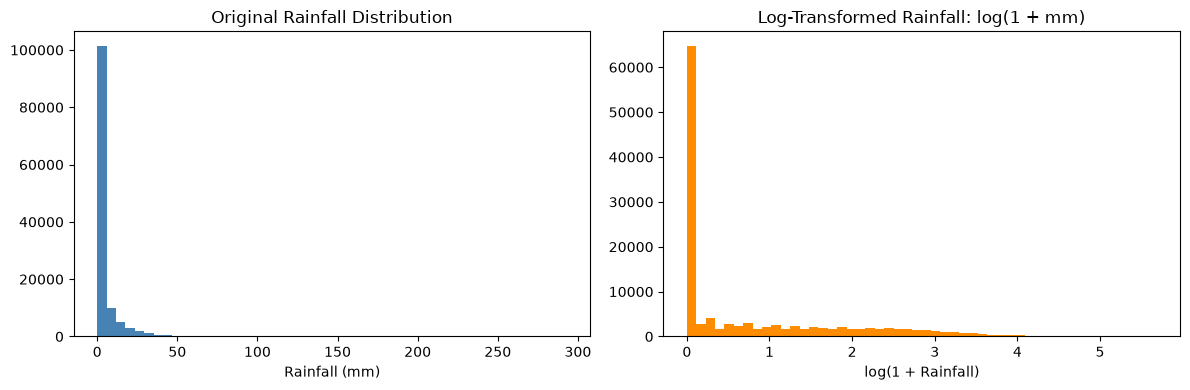

In [11]:
# Create cyclical day-of-year features
day_of_year = df["date"].dt.day_of_year
days_in_year = np.where(df["date"].dt.is_leap_year, 366, 365)
angle = 2 * np.pi * (day_of_year - 1) / days_in_year

df["day_of_year_sin"] = np.sin(angle)
df["day_of_year_cos"] = np.cos(angle)

# Merge coastal distance into the full weather dataset
coastal_data = geo_features[["city", "coastal_distance_km"]]
df = df.merge(coastal_data, on="city", how="left", validate="many_to_one")

# Log1p transformation on rainfall
df["precipitation_log"] = np.log1p(df["precipitation_sum"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["precipitation_sum"], bins=50, color="steelblue")
axes[0].set_title("Original Rainfall Distribution")
axes[0].set_xlabel("Rainfall (mm)")

axes[1].hist(df["precipitation_log"], bins=50, color="darkorange")
axes[1].set_title("Log-Transformed Rainfall: log(1 + mm)")
axes[1].set_xlabel("log(1 + Rainfall)")

plt.tight_layout()
plt.show()

In [12]:
# Define the 8 temporal features
temporal_features = [
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_log",
    "wind_speed_10m_max",
    "day_of_year_sin",
    "day_of_year_cos"
]

# Check feature count
print("Number of temporal features:", len(temporal_features))

# Check missing values
print("\nMissing values in temporal features:")
print(df[temporal_features].isnull().sum().to_dict())

# Display raw statistics
print("\nRaw temporal statistics in df:")
display(df[temporal_features].agg(["min", "max", "mean"]).T)

Number of temporal features: 8

Missing values in temporal features:
{'temperature_2m_max': 0, 'temperature_2m_min': 0, 'temperature_2m_mean': 0, 'relative_humidity_2m_mean': 0, 'precipitation_log': 0, 'wind_speed_10m_max': 0, 'day_of_year_sin': 0, 'day_of_year_cos': 0}

Raw temporal statistics in df:


,min,max,mean
temperature_2m_max,-12.600000,48.300000,29.470548
temperature_2m_min,-21.700000,35.600000,19.963424
temperature_2m_mean,-15.400000,40.300000,24.299881
relative_humidity_2m_mean,6.000000,100.000000,68.038156
precipitation_log,0.000000,5.683920,0.792935
wind_speed_10m_max,2.200000,76.100000,14.640494
day_of_year_sin,-0.999991,0.999991,0.012583
day_of_year_cos,-1.000000,1.000000,-0.020485


## 5. Chronological Splitting & Independent Scaling

In [13]:
# Chronological split boundaries identical to V1
train_end = pd.Timestamp("2024-10-10")
val_end = pd.Timestamp("2025-10-19")

train_df = df[df["date"] <= train_end].copy()
val_df = df[(df["date"] > train_end) & (df["date"] <= val_end)].copy()
test_df = df[df["date"] > val_end].copy()

print(f"Train split shape: {train_df.shape} ({train_df['date'].min().date()} to {train_df['date'].max().date()})")
print(f"Val split shape:   {val_df.shape} ({val_df['date'].min().date()} to {val_df['date'].max().date()})")
print(f"Test split shape:  {test_df.shape} ({test_df['date'].min().date()} to {test_df['date'].max().date()})")

print("Confirming all splits are initially in raw Celsius:")
print("Train temp_max min/max:", train_df["temperature_2m_max"].min(), "to", train_df["temperature_2m_max"].max())
print("Val   temp_max min/max:", val_df["temperature_2m_max"].min(), "to", val_df["temperature_2m_max"].max())
print("Test  temp_max min/max:", test_df["temperature_2m_max"].min(), "to", test_df["temperature_2m_max"].max())

Train split shape: (87250, 23) (2020-01-01 to 2024-10-10)
Val split shape:   (18700, 23) (2024-10-11 to 2025-10-19)
Test split shape:  (18750, 23) (2025-10-20 to 2026-10-29)
Confirming all splits are initially in raw Celsius:
Train temp_max min/max: -12.6 to 48.3
Val   temp_max min/max: -9.9 to 45.5
Test  temp_max min/max: -8.5 to 44.8


In [14]:
from sklearn.preprocessing import MinMaxScaler

temporal_scaler = MinMaxScaler()

# Fit strictly on the training set
temporal_scaler.fit(train_df[temporal_features])

# Transform using direct column assignment to preserve numeric types without LossySetitemError
train_df[temporal_features] = temporal_scaler.transform(train_df[temporal_features])
val_df[temporal_features] = temporal_scaler.transform(val_df[temporal_features])
test_df[temporal_features] = temporal_scaler.transform(test_df[temporal_features])

print("Temporal scaling complete! Verifying each split independently:")
print("Train features min/max:", train_df[temporal_features].agg(["min", "max"]).T)
print("Val features min/max:", val_df[temporal_features].agg(["min", "max"]).T)

Temporal scaling complete! Verifying each split independently:
Train features min/max:                            min  max
temperature_2m_max         0.0  1.0
temperature_2m_min         0.0  1.0
temperature_2m_mean        0.0  1.0
relative_humidity_2m_mean  0.0  1.0
precipitation_log          0.0  1.0
wind_speed_10m_max         0.0  1.0
day_of_year_sin            0.0  1.0
day_of_year_cos            0.0  1.0
Val features min/max:                                 min       max
temperature_2m_max         0.044335  0.954023
temperature_2m_min        -0.007030  0.959578
temperature_2m_mean       -0.016423  0.968978
relative_humidity_2m_mean -0.010753  0.989247
precipitation_log          0.000000  0.955597
wind_speed_10m_max         0.005413  0.737483
day_of_year_sin            0.000000  1.000000
day_of_year_cos            0.000019  1.000000


## 6. Geographical Scaling & Unscaled Target Integration

In [15]:
# Model A (without coastal distance) and Model B (with coastal distance)
geo_features_A = ["latitude", "longitude", "elevation_m"]
geo_features_B = geo_features_A + ["coastal_distance_km"]

geo_scaler_A = MinMaxScaler()
geo_scaler_B = MinMaxScaler()

geo_scaler_A.fit(geo_features[geo_features_A])
geo_scaler_B.fit(geo_features[geo_features_B])

geo_scaled_A = geo_features.copy()
geo_scaled_B = geo_features.copy()

geo_scaled_A[geo_features_A] = geo_scaler_A.transform(geo_features[geo_features_A])
geo_scaled_B[geo_features_B] = geo_scaler_B.transform(geo_features[geo_features_B])

print("Model A geo range:", geo_scaled_A[geo_features_A].agg(["min", "max"]))
print("Model B geo range:", geo_scaled_B[geo_features_B].agg(["min", "max"]))

Model A geo range:      latitude  longitude  elevation_m
min       0.0        0.0          0.0
max       1.0        1.0          1.0
Model B geo range:      latitude  longitude  elevation_m  coastal_distance_km
min       0.0        0.0          0.0                  0.0
max       1.0        1.0          1.0                  1.0


In [16]:
import json

# Combine scaled temporal splits
full_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
full_df = full_df.sort_values(["city", "date"]).reset_index(drop=True)

# Merge original Celsius temperature_2m_max as target source
raw_df = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw_targets = raw_df[["city", "date", "temperature_2m_max"]].rename(
    columns={"temperature_2m_max": "temperature_2m_max_raw"}
)

full_df = full_df.merge(raw_targets, on=["city", "date"], how="left", validate="one_to_one")
train_df = train_df.merge(raw_targets, on=["city", "date"], how="left", validate="one_to_one")

# Target scaler strictly fitted on original Celsius training targets
target_scaler = MinMaxScaler()
target_scaler.fit(train_df[["temperature_2m_max_raw"]])

# Load city-to-ID mapping
CITY_MAP_PATH = PROJECT_ROOT / "data" / "processed" / "artifacts" / "city_to_id.json"
with open(CITY_MAP_PATH, "r") as f:
    city_to_id = json.load(f)

print(f"Target scaler fitted on Celsius targets: min={target_scaler.data_min_[0]:.2f}°C, max={target_scaler.data_max_[0]:.2f}°C")
print("full_df scaled temporal ranges:", full_df[temporal_features].agg(["min", "max"]).T)
print("full_df raw target statistics:", full_df["temperature_2m_max_raw"].describe())

Target scaler fitted on Celsius targets: min=-12.60°C, max=48.30°C
full_df scaled temporal ranges:                                 min  max
temperature_2m_max         0.000000  1.0
temperature_2m_min        -0.007030  1.0
temperature_2m_mean       -0.016423  1.0
relative_humidity_2m_mean -0.010753  1.0
precipitation_log          0.000000  1.0
wind_speed_10m_max         0.000000  1.0
day_of_year_sin            0.000000  1.0
day_of_year_cos            0.000000  1.0
full_df raw target statistics: count    124700.000000
mean         29.470548
std           6.766488
min         -12.600000
25%          26.900000
50%          30.200000
75%          33.300000
max          48.300000
Name: temperature_2m_max_raw, dtype: float64


## 7. Sequence Generation (30 Days Lookback)

In [17]:
def create_multivariate_sequences(
    data,
    temporal_features,
    geo_scaled_A,
    geo_scaled_B,
    geo_features_A,
    geo_features_B,
    city_to_id,
    target_scaler,
    sequence_length=30
):
    X_weather = []
    X_geo_A = []
    X_geo_B = []
    city_ids = []
    y = []
    target_dates = []

    for city in data["city"].unique():
        city_data = (
            data[data["city"] == city]
            .sort_values("date")
            .reset_index(drop=True)
        )

        weather_values = city_data[temporal_features].to_numpy(dtype=np.float32)
        target_values = target_scaler.transform(
            city_data[["temperature_2m_max_raw"]]
        ).astype(np.float32)

        geo_A = geo_scaled_A[geo_scaled_A["city"] == city][geo_features_A].to_numpy(dtype=np.float32)[0]
        geo_B = geo_scaled_B[geo_scaled_B["city"] == city][geo_features_B].to_numpy(dtype=np.float32)[0]
        city_id = city_to_id[city]

        for i in range(sequence_length, len(city_data)):
            X_weather.append(weather_values[i-sequence_length:i])
            X_geo_A.append(geo_A)
            X_geo_B.append(geo_B)
            city_ids.append(city_id)
            y.append(target_values[i])
            target_dates.append(city_data.loc[i, "date"])

    return (
        np.array(X_weather, dtype=np.float32),
        np.array(X_geo_A, dtype=np.float32),
        np.array(X_geo_B, dtype=np.float32),
        np.array(city_ids, dtype=np.int64),
        np.array(y, dtype=np.float32),
        np.array(target_dates)
    )

In [18]:
import time

start_time = time.time()
(
    X_weather,
    X_geo_A,
    X_geo_B,
    city_ids,
    y,
    target_dates
) = create_multivariate_sequences(
    data=full_df,
    temporal_features=temporal_features,
    geo_scaled_A=geo_scaled_A,
    geo_scaled_B=geo_scaled_B,
    geo_features_A=geo_features_A,
    geo_features_B=geo_features_B,
    city_to_id=city_to_id,
    target_scaler=target_scaler,
    sequence_length=30
)

print(f"Sequences generated in {time.time() - start_time:.2f}s")
print("Weather sequences:", X_weather.shape)
print("Model A geography:", X_geo_A.shape)
print("Model B geography:", X_geo_B.shape)
print("City IDs:         ", city_ids.shape)
print("Targets:          ", y.shape)
print("Target dates:     ", target_dates.shape)

Sequences generated in 3.39s
Weather sequences: (123200, 30, 8)
Model A geography: (123200, 3)
Model B geography: (123200, 4)
City IDs:          (123200,)
Targets:           (123200, 1)
Target dates:      (123200,)


## 8. Chronological Sequence Masking & PyTorch DataLoaders

In [19]:
target_dates = pd.to_datetime(target_dates)

train_mask = target_dates <= train_end
val_mask = (target_dates > train_end) & (target_dates <= val_end)
test_mask = target_dates > val_end

X_train, X_val, X_test = X_weather[train_mask], X_weather[val_mask], X_weather[test_mask]
geo_train_A, geo_val_A, geo_test_A = X_geo_A[train_mask], X_geo_A[val_mask], X_geo_A[test_mask]
geo_train_B, geo_val_B, geo_test_B = X_geo_B[train_mask], X_geo_B[val_mask], X_geo_B[test_mask]
city_train, city_val, city_test = city_ids[train_mask], city_ids[val_mask], city_ids[test_mask]
y_train, y_val, y_test = y[train_mask], y[val_mask], y[test_mask]

print(f"TRAIN: weather={X_train.shape}, y={y_train.shape} | Weather range: [{X_train.min():.4f}, {X_train.max():.4f}] | Target range: [{y_train.min():.4f}, {y_train.max():.4f}]")
print(f"VAL:   weather={X_val.shape}, y={y_val.shape}     | Weather range: [{X_val.min():.4f}, {X_val.max():.4f}]   | Target range: [{y_val.min():.4f}, {y_val.max():.4f}]")
print(f"TEST:  weather={X_test.shape}, y={y_test.shape}    | Weather range: [{X_test.min():.4f}, {X_test.max():.4f}] | Target range: [{y_test.min():.4f}, {y_test.max():.4f}]")

TRAIN: weather=(85750, 30, 8), y=(85750, 1) | Weather range: [0.0000, 1.0000] | Target range: [0.0000, 1.0000]
VAL:   weather=(18700, 30, 8), y=(18700, 1)     | Weather range: [-0.0164, 1.0000]   | Target range: [0.0443, 0.9540]
TEST:  weather=(18750, 30, 8), y=(18750, 1)    | Weather range: [0.0000, 1.0000] | Target range: [0.0673, 0.9425]


In [20]:
import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 128

train_loader_A = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(geo_train_A, dtype=torch.float32),
        torch.tensor(city_train, dtype=torch.long),
        torch.tensor(y_train, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_A = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(geo_val_A, dtype=torch.float32),
        torch.tensor(city_val, dtype=torch.long),
        torch.tensor(y_val, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_A = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(geo_test_A, dtype=torch.float32),
        torch.tensor(city_test, dtype=torch.long),
        torch.tensor(y_test, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

train_loader_B = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(geo_train_B, dtype=torch.float32),
        torch.tensor(city_train, dtype=torch.long),
        torch.tensor(y_train, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_B = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(geo_val_B, dtype=torch.float32),
        torch.tensor(city_val, dtype=torch.long),
        torch.tensor(y_val, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_B = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(geo_test_B, dtype=torch.float32),
        torch.tensor(city_test, dtype=torch.long),
        torch.tensor(y_test, dtype=torch.float32)
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"DataLoaders ready! Batches -> Train: {len(train_loader_A)}, Val: {len(val_loader_A)}, Test: {len(test_loader_A)}")

Device: cuda
DataLoaders ready! Batches -> Train: 670, Val: 147, Test: 147


## 9. Multivariate LSTM Architecture

In [21]:
import torch.nn as nn

class MultivariateWeatherLSTM(nn.Module):
    def __init__(
        self,
        input_size=8,
        hidden_size=64,
        num_cities=50,
        embedding_dim=8,
        geo_dim=3
    ):
        super().__init__()
        self.city_embedding = nn.Embedding(num_cities, embedding_dim)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )
        combined_size = hidden_size + embedding_dim + geo_dim
        self.fc = nn.Linear(combined_size, 1)

    def forward(self, weather, geography, city_id):
        lstm_output, (hidden_state, cell_state) = self.lstm(weather)
        final_hidden = hidden_state[-1]
        city_vector = self.city_embedding(city_id)
        combined = torch.cat([final_hidden, geography, city_vector], dim=1)
        prediction = self.fc(combined)
        return prediction

In [22]:
torch.manual_seed(42)
model_A = MultivariateWeatherLSTM(
    input_size=8,
    hidden_size=64,
    num_cities=50,
    embedding_dim=8,
    geo_dim=3
).to(device)

torch.manual_seed(42)
model_B = MultivariateWeatherLSTM(
    input_size=8,
    hidden_size=64,
    num_cities=50,
    embedding_dim=8,
    geo_dim=4
).to(device)

print("Model A parameters:", sum(p.numel() for p in model_A.parameters()))
print("Model B parameters:", sum(p.numel() for p in model_B.parameters()))

# Quick sanity check on dummy batch
w_b, g_b, c_b, _ = next(iter(train_loader_A))
with torch.no_grad():
    out_A = model_A(w_b.to(device), g_b.to(device), c_b.to(device))
print("Model A sanity batch output shape:", out_A.shape)

Model A parameters: 19420
Model B parameters: 19421
Model A sanity batch output shape: torch.Size([128, 1])


## 10. Model Training (Model A & Model B)

In [23]:
import os
import torch.optim as optim

os.makedirs("../models", exist_ok=True)
criterion = nn.MSELoss()

def train_model(model, train_loader, val_loader, model_name,
                epochs=30, patience=5, learning_rate=0.001):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    best_val_loss = float("inf")
    best_epoch = 0
    patience_counter = 0
    history = []
    model_path = f"../models/best_multivariate_model_{model_name}.pth"

    print(f"\n--- Training Model {model_name} ---")
    for epoch in range(epochs):
        model.train()
        train_total_loss = 0.0
        train_samples = 0

        for weather, geography, city, target in train_loader:
            weather = weather.to(device)
            geography = geography.to(device)
            city = city.to(device)
            target = target.to(device)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(weather, geography, city)
            loss = criterion(predictions, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_total_loss += loss.item() * weather.size(0)
            train_samples += weather.size(0)

        train_loss = train_total_loss / train_samples

        # Validation
        model.eval()
        val_total_loss = 0.0
        val_samples = 0

        with torch.no_grad():
            for weather, geography, city, target in val_loader:
                weather = weather.to(device)
                geography = geography.to(device)
                city = city.to(device)
                target = target.to(device)

                predictions = model(weather, geography, city)
                loss = criterion(predictions, target)
                val_total_loss += loss.item() * weather.size(0)
                val_samples += weather.size(0)

        val_loss = val_total_loss / val_samples
        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            patience_counter = 0
            torch.save(model.state_dict(), model_path)
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    print(f"Model {model_name} - Best Epoch: {best_epoch}, Best Val Loss: {best_val_loss:.6f}")
    return model, history

In [24]:
# Train Model A
torch.manual_seed(42)
model_A = MultivariateWeatherLSTM(
    input_size=8,
    hidden_size=64,
    num_cities=50,
    embedding_dim=8,
    geo_dim=3
).to(device)

model_A, history_A = train_model(
    model_A,
    train_loader_A,
    val_loader_A,
    model_name="A"
)


--- Training Model A ---
Epoch [01/30] Train Loss: 0.012362 | Val Loss: 0.000923
Epoch [02/30] Train Loss: 0.000789 | Val Loss: 0.000772
Epoch [03/30] Train Loss: 0.000678 | Val Loss: 0.000684
Epoch [04/30] Train Loss: 0.000617 | Val Loss: 0.000651
Epoch [05/30] Train Loss: 0.000567 | Val Loss: 0.000589
Epoch [06/30] Train Loss: 0.000551 | Val Loss: 0.000574
Epoch [07/30] Train Loss: 0.000540 | Val Loss: 0.000560
Epoch [08/30] Train Loss: 0.000527 | Val Loss: 0.000563
Epoch [09/30] Train Loss: 0.000529 | Val Loss: 0.000547
Epoch [10/30] Train Loss: 0.000521 | Val Loss: 0.000591
Epoch [11/30] Train Loss: 0.000521 | Val Loss: 0.000559
Epoch [12/30] Train Loss: 0.000517 | Val Loss: 0.000617
Epoch [13/30] Train Loss: 0.000517 | Val Loss: 0.000566
Epoch [14/30] Train Loss: 0.000512 | Val Loss: 0.000594
Early stopping at epoch 14
Model A - Best Epoch: 9, Best Val Loss: 0.000547


In [25]:
# Train Model B (with coastal distance)
torch.manual_seed(42)
model_B = MultivariateWeatherLSTM(
    input_size=8,
    hidden_size=64,
    num_cities=50,
    embedding_dim=8,
    geo_dim=4
).to(device)

model_B, history_B = train_model(
    model_B,
    train_loader_B,
    val_loader_B,
    model_name="B"
)


--- Training Model B ---
Epoch [01/30] Train Loss: 0.012680 | Val Loss: 0.000886
Epoch [02/30] Train Loss: 0.000786 | Val Loss: 0.000770
Epoch [03/30] Train Loss: 0.000673 | Val Loss: 0.001022
Epoch [04/30] Train Loss: 0.000616 | Val Loss: 0.000685
Epoch [05/30] Train Loss: 0.000559 | Val Loss: 0.000643
Epoch [06/30] Train Loss: 0.000548 | Val Loss: 0.000557
Epoch [07/30] Train Loss: 0.000538 | Val Loss: 0.000594
Epoch [08/30] Train Loss: 0.000531 | Val Loss: 0.000558
Epoch [09/30] Train Loss: 0.000525 | Val Loss: 0.000552
Epoch [10/30] Train Loss: 0.000518 | Val Loss: 0.000604
Epoch [11/30] Train Loss: 0.000519 | Val Loss: 0.000543
Epoch [12/30] Train Loss: 0.000510 | Val Loss: 0.000534
Epoch [13/30] Train Loss: 0.000510 | Val Loss: 0.000564
Epoch [14/30] Train Loss: 0.000510 | Val Loss: 0.000533
Epoch [15/30] Train Loss: 0.000508 | Val Loss: 0.000560
Epoch [16/30] Train Loss: 0.000509 | Val Loss: 0.000533
Epoch [17/30] Train Loss: 0.000503 | Val Loss: 0.000530
Epoch [18/30] Train Lo

## 11. Evaluation on Test Set (Celsius) & V1 Benchmark Comparison

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(model, test_loader, target_scaler, model_name):
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for weather, geography, city, target in test_loader:
            weather = weather.to(device)
            geography = geography.to(device)
            city = city.to(device)

            preds = model(weather, geography, city)
            all_preds.append(preds.cpu().numpy())
            all_targets.append(target.numpy())

    preds_norm = np.vstack(all_preds)
    targets_norm = np.vstack(all_targets)

    # Invert target scaling back to original Celsius
    preds_celsius = target_scaler.inverse_transform(preds_norm)
    targets_celsius = target_scaler.inverse_transform(targets_norm)

    mae = mean_absolute_error(targets_celsius, preds_celsius)
    rmse = np.sqrt(mean_squared_error(targets_celsius, preds_celsius))
    r2 = r2_score(targets_celsius, preds_celsius)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "preds_celsius": preds_celsius,
        "targets_celsius": targets_celsius
    }

results_A = evaluate_model(model_A, test_loader_A, target_scaler, "A")
results_B = evaluate_model(model_B, test_loader_B, target_scaler, "B")

comparison_df = pd.DataFrame({
    "Model Architecture": [
        "V1 Benchmark (Univariate + City Embeddings)",
        "Model A (8 Temporal + 3 Geo + City Embeddings)",
        "Model B (8 Temporal + 4 Geo with Coastal + City Embeddings)"
    ],
    "MAE (°C)": [1.0373, results_A["MAE"], results_B["MAE"]],
    "RMSE (°C)": [1.4527, results_A["RMSE"], results_B["RMSE"]],
    "R² Score": [0.9501, results_A["R2"], results_B["R2"]]
})

display(comparison_df.round(4))

,Model Architecture,MAE (°C),RMSE (°C),R² Score
0,V1 Benchmark (Univariate + City Embeddings),1.0373,1.4527,0.9501
1,Model A (8 Temporal + 3 Geo + City Embeddings),1.0057,1.3972,0.9538
2,Model B (8 Temporal + 4 Geo with Coastal + Cit...,0.9827,1.3797,0.9550


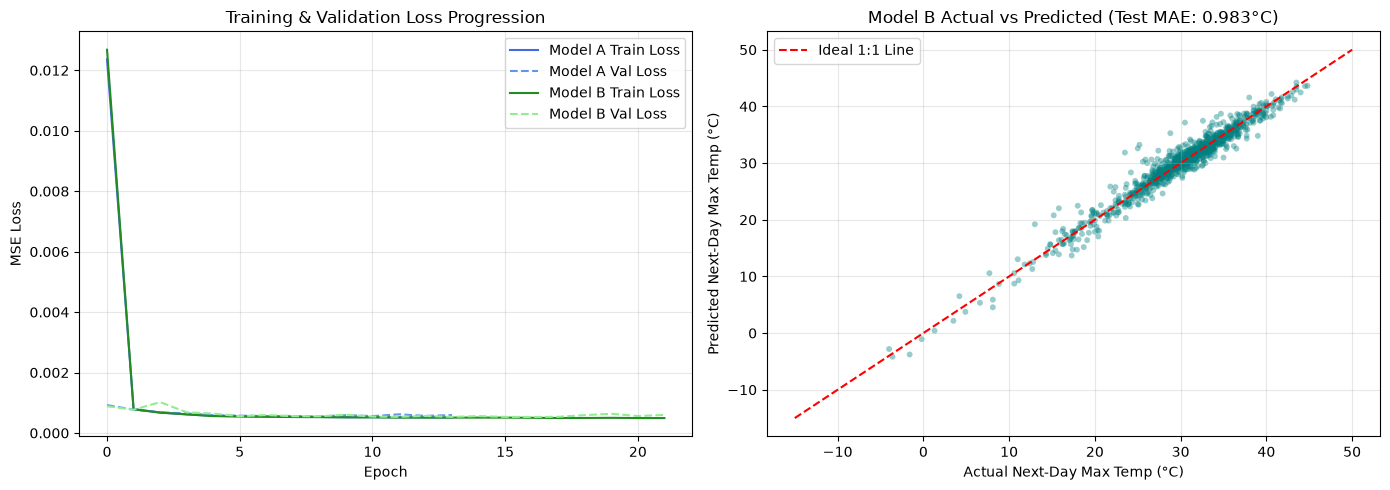

In [27]:
# Plot Training Loss Curves and Predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot([h["train_loss"] for h in history_A], label="Model A Train Loss", color="royalblue")
axes[0].plot([h["val_loss"] for h in history_A], label="Model A Val Loss", color="cornflowerblue", linestyle="--")
axes[0].plot([h["train_loss"] for h in history_B], label="Model B Train Loss", color="forestgreen")
axes[0].plot([h["val_loss"] for h in history_B], label="Model B Val Loss", color="lightgreen", linestyle="--")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training & Validation Loss Progression")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Scatter plot: Model B Predictions vs Actuals
sample_idx = np.random.choice(len(results_B["targets_celsius"]), 1000, replace=False)
axes[1].scatter(
    results_B["targets_celsius"][sample_idx],
    results_B["preds_celsius"][sample_idx],
    alpha=0.4,
    s=18,
    color="teal",
    edgecolor="none"
)
axes[1].plot([-15, 50], [-15, 50], "r--", linewidth=1.5, label="Ideal 1:1 Line")
axes[1].set_xlabel("Actual Next-Day Max Temp (°C)")
axes[1].set_ylabel("Predicted Next-Day Max Temp (°C)")
axes[1].set_title(f"Model B Actual vs Predicted (Test MAE: {results_B['MAE']:.3f}°C)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("Project root exists:", PROJECT_ROOT.exists())

Project root: d:\PG Study material\Foundations of AI\LSTM_explainer
Project root exists: True


In [29]:
import json
import joblib
from pathlib import Path

# Create a separate V2 artifact directory
ARTIFACT_DIR_V2 = (
    PROJECT_ROOT / "data" / "processed" / "artifacts" / "v2"
)

ARTIFACT_DIR_V2.mkdir(parents=True, exist_ok=True)

# Save preprocessing scalers
joblib.dump(
    temporal_scaler,
    ARTIFACT_DIR_V2 / "temporal_scaler.pkl"
)

joblib.dump(
    target_scaler,
    ARTIFACT_DIR_V2 / "target_scaler.pkl"
)

joblib.dump(
    geo_scaler_A,
    ARTIFACT_DIR_V2 / "geo_scaler_A.pkl"
)

joblib.dump(
    geo_scaler_B,
    ARTIFACT_DIR_V2 / "geo_scaler_B.pkl"
)

# Save city mapping
with open(ARTIFACT_DIR_V2 / "city_to_id.json", "w") as f:
    json.dump(city_to_id, f, indent=4)

# Save geographical metadata
geo_features.to_csv(
    ARTIFACT_DIR_V2 / "geographical_features.csv",
    index=False
)

# Save model configuration
config_v2 = {
    "version": "V2",
    "sequence_length": 30,
    "input_size": 8,
    "hidden_size": 64,
    "num_cities": len(city_to_id),
    "embedding_dim": 8,
    "temporal_features": temporal_features,
    "model_A": {
        "geo_features": geo_features_A,
        "geo_dim": 3
    },
    "model_B": {
        "geo_features": geo_features_B,
        "geo_dim": 4
    },
    "target": "temperature_2m_max_raw",
    "target_unit": "Celsius",
    "train_end": "2024-10-10",
    "validation_end": "2025-10-19"
}

with open(ARTIFACT_DIR_V2 / "config.json", "w") as f:
    json.dump(config_v2, f, indent=4)

print("V2 artifacts saved successfully!")

for file in sorted(ARTIFACT_DIR_V2.iterdir()):
    print(file.name)

V2 artifacts saved successfully!
city_to_id.json
config.json
geo_scaler_A.pkl
geo_scaler_B.pkl
geographical_features.csv
target_scaler.pkl
temporal_scaler.pkl


In [30]:
from pathlib import Path

MODEL_DIR = PROJECT_ROOT / "models"

model_files = [
    "best_weather_lstm.pth",
    "best_multivariate_model_A.pth",
    "best_multivariate_model_B.pth"
]

for filename in model_files:
    path = MODEL_DIR / filename

    print(
        filename,
        "->",
        "FOUND" if path.exists() else "MISSING"
    )

best_weather_lstm.pth -> FOUND
best_multivariate_model_A.pth -> FOUND
best_multivariate_model_B.pth -> FOUND


In [31]:
print("X_test:", X_test.shape)
print("geo_test_A:", geo_test_A.shape)
print("geo_test_B:", geo_test_B.shape)
print("city_test:", city_test.shape)
print("y_test:", y_test.shape)
print("target_dates:", target_dates.shape)

X_test: (18750, 30, 8)
geo_test_A: (18750, 3)
geo_test_B: (18750, 4)
city_test: (18750,)
y_test: (18750, 1)
target_dates: (123200,)


In [35]:
print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("Total dates:", len(target_dates))
print("Total sequences:", len(X_weather))

Train samples: 85750
Validation samples: 18700
Test samples: 18750
Total dates: 123200
Total sequences: 123200


In [32]:
from pathlib import Path

TEST_ARTIFACT_DIR = Path(
    "../data/processed/artifacts/v2/test"
)

TEST_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Test artifact directory:", TEST_ARTIFACT_DIR.resolve())

Test artifact directory: D:\PG Study material\Foundations of AI\LSTM_explainer\data\processed\artifacts\v2\test


In [37]:
import numpy as np

# Save test inputs and targets
np.save(TEST_ARTIFACT_DIR / "X_test.npy", X_test)

np.save(TEST_ARTIFACT_DIR / "geo_test_A.npy", geo_test_A)
np.save(TEST_ARTIFACT_DIR / "geo_test_B.npy", geo_test_B)

np.save(TEST_ARTIFACT_DIR / "city_test.npy", city_test)
np.save(TEST_ARTIFACT_DIR / "y_test.npy", y_test)

np.save(
    TEST_ARTIFACT_DIR / "target_dates.npy",
    target_dates
)

print("All test arrays saved successfully!")

All test arrays saved successfully!


In [34]:
for file in TEST_ARTIFACT_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

city_test.npy - 146.61 KB
geo_test_A.npy - 219.85 KB
geo_test_B.npy - 293.09 KB
target_dates.npy - 962.62 KB
X_test.npy - 17578.25 KB
y_test.npy - 73.37 KB
